# Présentation générale des JO 2020 (Tokyo)

## Contexte de l'édition

Les Jeux Olympiques d'été de 2020 se sont déroulés à **Tokyo**, au **Japon**, du **23 juillet au 8 août 2021**. Ils ont été marqués par la pandémie du **COVID-19** et ont été reportés d'un an.

### Informations clés

| Information | Détail |
|------------|--------|
| **Libellé officiel** | 2020 Summer Olympics |
| **Numéro d'édition** | XXXIIe Olympiade |
| **Ville hôte** | Tokyo, Japon |
| **Dates d'ouverture** | 23 juillet |
| **Dates de clôture** | 8 août |
| **Saison** | Été |

### Contexte historique

- **Première édition à Tokyo** : 1964 (XVIIIe Olympiade)
- **Tokyo 2020** est donc la **deuxième fois** que la capitale japonaise accueille les Jeux Olympiques d'été
- C'est la **quatrième fois** que le Japon organise les Jeux Olympiques (incluant deux éditions hivernales : Sapporo 1972 et Nagano 1998)

### Particularités de cette édition

1. **Report historique** : Premiers Jeux Olympiques reportés dans l'histoire moderne (hors guerres mondiales)
2. **Organisation à huis clos** : La plupart des épreuves se sont déroulées sans spectateurs
3. **Parité hommes/femmes** : Premiers JO d'été avec une stricte parité du nombre d'athlètes participants
4. **Nouvelles disciplines** : Introduction du skateboard, surf, escalade sportive, karaté, et retour du baseball/softball

---

## Sports et épreuves présents

### Sports au programme

Les JO 2020 comptaient **33 sports** et **50 disciplines**, avec un total de **339 épreuves**.

**Nouveautés par rapport aux éditions précédentes :**
- Skateboard (street et park)
- Surf
- Escalade sportive
- Karaté
- Baseball (hommes) et Softball (femmes) - retour après 2008

### Répartition par genre des épreuves

Les JO 2020 ont atteint la parité avec :

- **157 épreuves masculines**
- **157 épreuves féminines**  
- **25 épreuves mixtes**

C'est une avancée majeure pour l'égalité des genres dans l'histoire olympique.

---

## Analyse des athlètes participants

### Âge des athlètes

- **Âge moyen** : environ 26-27 ans
- **Athlète la plus jeune** : Kokona Hiraki (Japon, skateboard) - 12 ans
- **Athlète le plus âgé** : Mary Hanna (Australie, équitation) - 66 ans

### Taille et poids

| Caractéristique | Moyenne |
|----------------|---------|
| Taille | ~175 cm |
| Poids | ~70 kg |

*Les valeurs varient considérablement selon les sports (les gymnastes sont généralement plus petits et légers que les basketteurs ou les nageurs).*

---

## Localisation géographique

Tokyo est située sur l'île de **Honshū**, la plus grande île de l'archipel japonais, dans la région du **Kantō**.

Les sites de compétition étaient répartis en deux zones principales :
- **Zone Héritage** : Sites déjà utilisés lors des JO 1964
- **Zone de Tokyo Bay** : Sites construits sur l'île artificielle d'Odaiba

---

In [39]:
# Compléter ici les imports dont vous avez besoin, ne pas modifier ceux déjà présents
import getpass
from os import getenv
import pandas as pd
import numpy as np
import oracledb
import warnings
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import math

In [40]:
# Nécessaire pour éviter les problèmes de session
class Connexion(object):
    def __init__(self, login, password):
        self.conn = oracledb.connect(
            user=login,
            password=password,
            host="oracle.iut-orsay.fr",
            port=1521,
            sid="etudom",
        )
        self.conn.autocommit = False

    def __enter__(self):
        self.conn.autocommit = False
        return self.conn

    def __exit__(self, *args):
        self.conn.close()

In [41]:
# La fonction ci-dessous est à utiliser pour exécuter une requête et stocker les résultats dans un dataframe Pandas sans afficher d’alerte.
# Vous pouvez vous en inspirer pour créer vos propres fonctions.
def requete_vers_dataframe(connexion_data, requete, valeurs = None):
    with Connexion(login=connexion_data['login'], password=connexion_data['password']) as connexion:
        warnings.simplefilter(action='ignore', category=UserWarning)
        if valeurs is not None:
            df = pd.read_sql(requete, connexion, params=valeurs)
        else:
            df = pd.read_sql(requete, connexion)
        warnings.simplefilter("always") 
        return df

In [42]:
# Saisir ci-dessous l'édition des JO qui vous a été attribuée. Cela correspond au LibelleHote dans la table HOTE de la base de données
# Par exemple EDITION_JO = "2020 Summer Olympics"
EDITION_JO = "2020 Summer Olympics"
EDITION_TOKYO ="2020 Summer Olympics"
EDITION_RIO="2016 Summer Olympics"
EDITION_PYEONG="2018 Winter Olympics"
# Saisir ci-dessous le login court de la base utilisée pour votre carnet
SCHEMA = "ALAHRE1"

In [44]:
# On demande à l'utilisateur son login et mot de passe pour pouvoir accéder à la base de données
if getenv("DB_LOGIN") is None:
    login = input("Login : ")
else:
    login = getenv("DB_LOGIN")
if getenv("DB_PASS") is None:
    password = getpass.getpass("Mot de passe : ")
else:
    password = getenv("DB_PASS")
conn = {'login': login, 'password': password}

Login :  alahre1
Mot de passe :  ········


In [45]:
# On vérifie que l'utilisateur est bien connecté à la base de données, que le schéma est bon, et qu'on trouve la bonne édition des JO
data = requete_vers_dataframe(conn, f"SELECT * FROM {SCHEMA}.HOTE WHERE LibelleHote LIKE (:libelle)",{"libelle":EDITION_JO})
id_hote = int(data.IDHOTE.iloc[0])
print(f"Identifiant de l’hôte : {id_hote}")

Identifiant de l’hôte : 61


# Partie II — Comparaison des JO Tokyo 2020 avec les éditions précédentes

Dans cette partie, nous comparons les **Jeux Olympiques d'été de Tokyo 2020** avec deux éditions précédentes :
- **Rio de Janeiro 2016** 
- **PyeongChang 2018** 

In [46]:
def get_id_hote(conn, libelle):
    data=requete_vers_dataframe(
        conn,
        f"SELECT * FROM {SCHEMA}.HOTE WHERE LibelleHote LIKE (:libelle)",
        {"libelle": libelle})
    return int(data.IDHOTE.iloc[0])

id_hote_tokyo=get_id_hote(conn, EDITION_TOKYO)
id_hote_rio=get_id_hote(conn, EDITION_RIO)
id_hote_pyeong=get_id_hote(conn, EDITION_PYEONG)

print(f"ID Tokyo 2020: {id_hote_tokyo}")
print(f"ID Rio 2016: {id_hote_rio}")
print(f"ID PyeongChang 2018: {id_hote_pyeong}")

ID Tokyo 2020: 61
ID Rio 2016: 59
ID PyeongChang 2018: 60


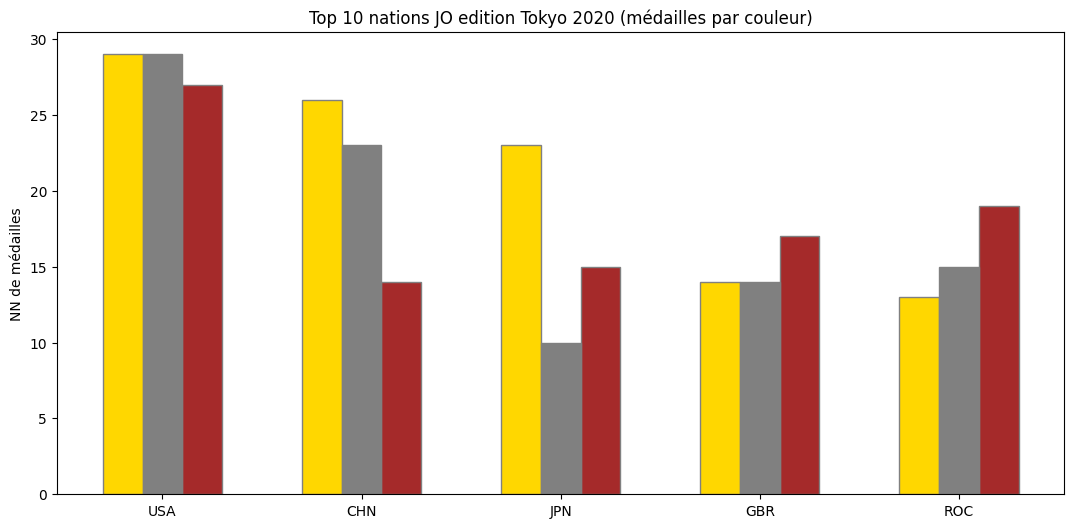

JAUNE : OR
GRIS : ARGENT
ROUGE : BRONZE

les USA dominent le classement à l'or, suivis de la Chine le Japon, pays hôte, réalise une performance historique avec 26 médailles d'or, son meilleur résultat aux JO d'été d'été.


In [47]:
# graphique baton: top 10 Tokyo 2020 selon couleur de medaille
top10=tokyo_med.head(5).set_index("NOC")
fig,ax=plt.subplots(figsize=(13, 6))
x=np.arange(len(top10))

w = 0.2
ax.bar(x-w,top10["OR_"],width=w, label="Or",color="gold", edgecolor="gray")
ax.bar(x+ w,top10["BRONZE"], width=w,label="bronze",color="brown",edgecolor="gray")
ax.bar(x,top10["ARGENT"],width=w,label="Argent",color="grey",edgecolor="gray")


ax.set_xticks(x)
ax.set_xticklabels(top10.index)
ax.set_title("Top 10 nations JO edition Tokyo 2020 (médailles par couleur)", fontsize=12)
ax.set_ylabel("NN de médailles")
plt.show()

print("""JAUNE : OR
GRIS : ARGENT
ROUGE : BRONZE

les USA dominent le classement à l'or, suivis de la Chine le Japon, pays hôte, réalise une performance historique avec 26 médailles d'or, son meilleur résultat aux JO d'été d'été.""")

In [48]:
# requête : tableau des médailles pour une édition
def tab_medailles(conn, id_hote):
    requete = f"""
        SELECT PI.NOC,
               SUM(CASE WHEN PI.Medaille='Gold'   THEN 1 ELSE 0 END) AS OR_,
               SUM(CASE WHEN PI.Medaille='Silver' THEN 1 ELSE 0 END) AS ARGENT,
               SUM(CASE WHEN PI.Medaille='Bronze' THEN 1 ELSE 0 END) AS BRONZE,
               COUNT(PI.Medaille) AS TOTAL
        FROM {SCHEMA}.PARTICIPATION_INDIVIDUELLE PI
        INNER JOIN {SCHEMA}.EVENEMENT E ON PI.IdEvent = E.IdEvenement
        WHERE E.IdHote = :id_hote
          AND PI.Medaille IS NOT NULL
        GROUP BY PI.NOC
        ORDER BY OR_ DESC, ARGENT DESC, BRONZE DESC
    """
    return requete_vers_dataframe(conn, requete, {"id_hote": id_hote})
tokyo_med=tab_medailles(conn, id_hote_tokyo)
rio_med=tab_medailles(conn, id_hote_rio)
pyeong_med=tab_medailles(conn, id_hote_pyeong)

print("top 10 JO edition tokyo 2020")
print(tokyo_med.head(10).to_string(index=False))

top 10 JO edition tokyo 2020
NOC  OR_  ARGENT  BRONZE  TOTAL
USA   29      29      27     86
CHN   26      23      14     63
JPN   23      10      15     49
GBR   14      14      17     45
ROC   13      15      19     47
AUS   11       4      13     28
NED    7       8      11     29
GER    7       5       9     22
ITA    6       9      14     29
CUB    6       3       5     14


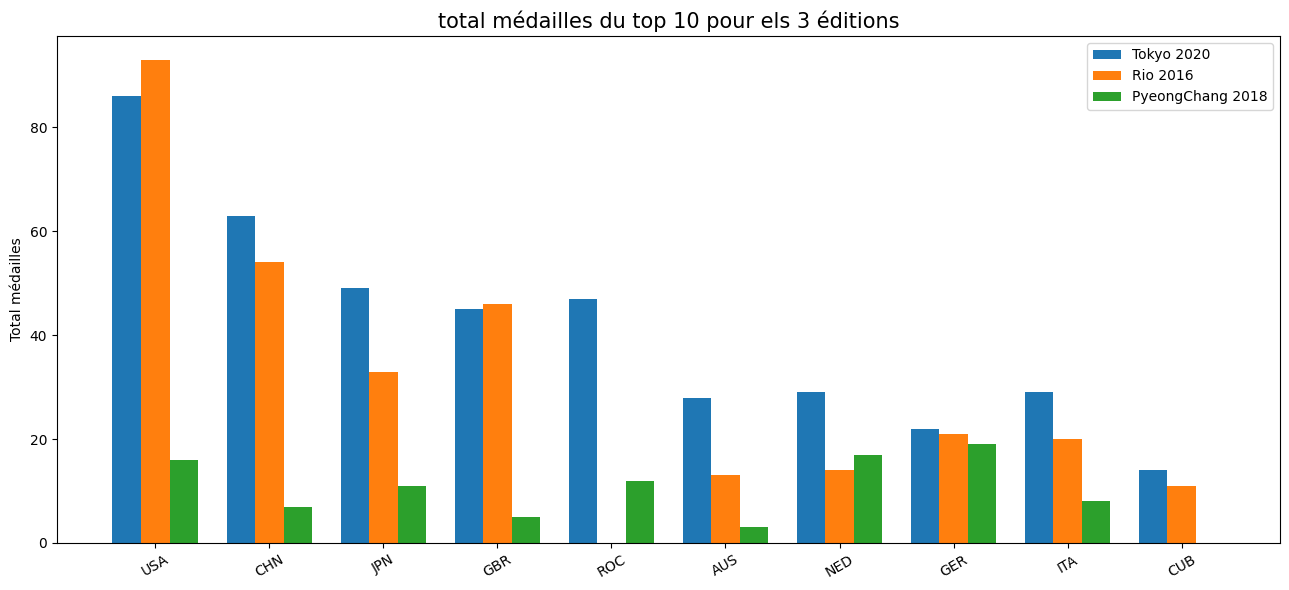


Les USA restent les premiers sur les 2 éditions d'été, mais leur total recule de 121 (Rio) à 113 (Tokyo). La Chine progresse légèrement. Les faibles valeurs pour PyeongChang s'expliquent par le programme réduit des Jeux d'hiver (102 épreuves
contre 306 à Rio et 339 à Tokyo).


In [49]:
# comparaison du nb total de médailles pour les 10 premiers pays des jo Tokyo 2020



top10_noc=tokyo_med.head(10)["NOC"].tolist()
tok_tot=tokyo_med[tokyo_med["NOC"].isin(top10_noc)].set_index("NOC")["TOTAL"]
rio_tot=rio_med[rio_med["NOC"].isin(top10_noc)].set_index("NOC")["TOTAL"]
pyeong_tot=pyeong_med[pyeong_med["NOC"].isin(top10_noc)].set_index("NOC")["TOTAL"]

compare = pd.DataFrame({
"Tokyo 2020":tok_tot,
"Rio 2016":rio_tot,
"PyeongChang 2018": pyeong_tot
}).fillna(0).loc[top10_noc]

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(len(compare))
w = 0.25
ax.bar(x-w,compare["Tokyo 2020"],width=w, label="Tokyo 2020")
ax.bar(x,compare["Rio 2016"],width=w, label="Rio 2016")
ax.bar(x+w,compare["PyeongChang 2018"],width=w, label="PyeongChang 2018")

ax.set_xticks(x)
ax.set_xticklabels(compare.index, rotation=30)
ax.set_title("total médailles du top 10 pour els 3 éditions",fontsize=15)
ax.set_ylabel("Total médailles")
ax.legend()
plt.tight_layout()
plt.show()
print("""
Les USA restent les premiers sur les 2 éditions d'été, mais leur total recule de 121 (Rio) à 113 (Tokyo). La Chine progresse légèrement. Les faibles valeurs pour PyeongChang s'expliquent par le programme réduit des Jeux d'hiver (102 épreuves
contre 306 à Rio et 339 à Tokyo).""")

## 3. Statistiques descriptives du total de médailles par pays

In [50]:
# ---------CALCUL Tokyo 2020-------
tot=list(tokyo_med["TOTAL"])
n=len(tot)

# moyenne
moyenne=sum(tot)/n

# variance + écart-type 
variance=sum((v-moyenne)**2 for v in tot)/n
ecart_type=variance**0.5

# Tri pour les quartiles et la médiane
tri=sorted(tot)
minimum=tri[0]
maximum=tri[-1]



print("--- Calcul JO edition Tokyo 2020 : total médailles par pays ---")
print(f"n={n}")
print(f"Minimum={minimum}")


print(f"Maximum={maximum}")
print(f"Moyenne={moyenne}")
print(f"Écart-type={ecart_type}")

--- Calcul JO edition Tokyo 2020 : total médailles par pays ---
n=91
Minimum=1
Maximum=86
Moyenne=8.868131868131869
Écart-type=13.808906817670048


In [51]:
#médailles par genre pour une édition
def medailles_par_genre(conn, id_hote):
    requete = f"""
        SELECT A.Genre,
               COUNT(PI.Medaille) AS NBMEDAILLES
        FROM {SCHEMA}.PARTICIPATION_INDIVIDUELLE PI
        INNER JOIN {SCHEMA}.EVENEMENT E ON PI.IdEvent   = E.IdEvenement
        INNER JOIN {SCHEMA}.ATHLETE   A ON PI.IdAthlete = A.IdAthlete
        WHERE E.IdHote = :id_hote
          AND PI.Medaille IS NOT NULL
        GROUP BY A.Genre"""
    return requete_vers_dataframe(conn, requete, {"id_hote": id_hote})

genre_tokyo =medailles_par_genre(conn, id_hote_tokyo)
genre_rio=medailles_par_genre(conn,id_hote_rio)
genre_pyeong= medailles_par_genre(conn, id_hote_pyeong)

print("Médailles par genre — Tokyo 2020 :")
print(genre_tokyo.to_string(index=False))

Médailles par genre — Tokyo 2020 :
 GENRE  NBMEDAILLES
  Male          434
Female          373


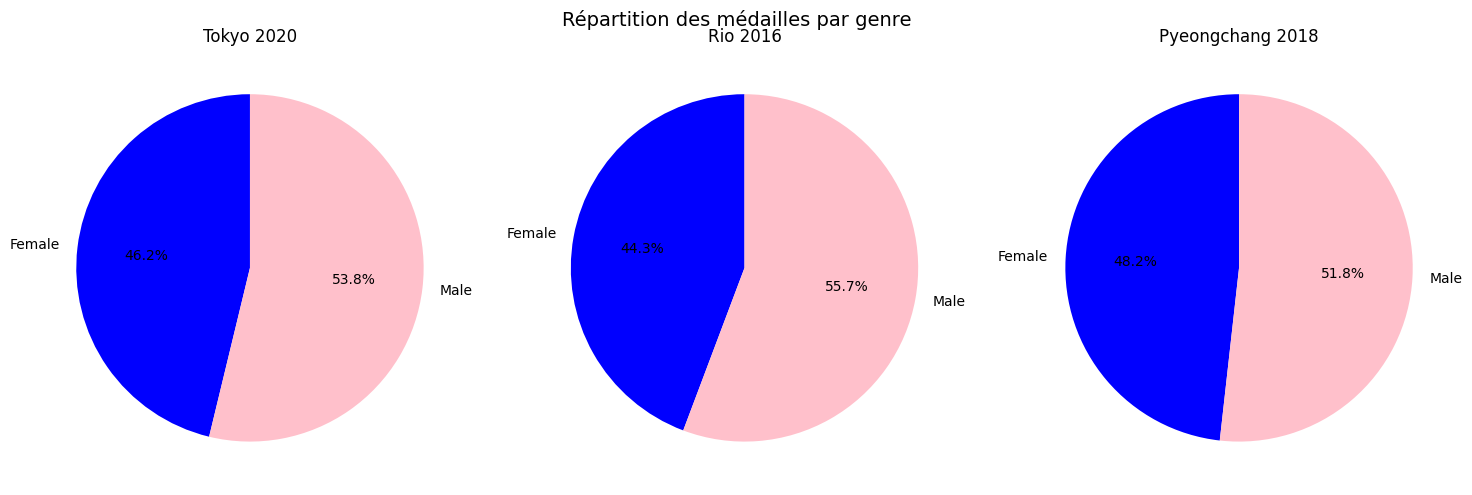

On observe une quasi parité hommes/femmes dans les deux éditions d'été, ce qui témoigne de la volonté d'inclusion féminines des organisateurs


In [52]:
# diagrammes ronds comparaison homme femme
fig,axes=plt.subplots(1,3,figsize=(15, 5))
titres=["Tokyo 2020", "Rio 2016", "Pyeongchang 2018"]
donnees=[genre_tokyo, genre_rio, genre_pyeong]
couleurs=["blue", "pink", "green"]

for ax, df, titre in zip(axes, donnees, titres):
    df_s=df.sort_values("GENRE")
    ax.pie(
        df_s["NBMEDAILLES"],
        labels=df_s["GENRE"],
        autopct="%1.1f%%",
        colors=couleurs[:len(df_s)],
        startangle=90
    )
    ax.set_title(titre, fontsize=12)

plt.suptitle("Répartition des médailles par genre", fontsize=14)
plt.tight_layout()
plt.show()

print("""On observe une quasi parité hommes/femmes dans les deux éditions d'été, ce qui témoigne de la volonté d'inclusion féminines des organisateurs""")

In [53]:
# nb athlètes distincts par genre pour une édition
def athletes_par_genre(conn, id_hote):
    requete=f"""
    SELECT A.Genre,
    COUNT(DISTINCT PI.IdAthlete) AS NBATHLETES
    FROM {SCHEMA}.PARTICIPATION_INDIVIDUELLE PI
    INNER JOIN {SCHEMA}.EVENEMENT E ON PI.IdEvent= E.IdEvenement
    INNER JOIN {SCHEMA}.ATHLETE A ON PI.IdAthlete= A.IdAthlete
    WHERE E.IdHote=:id_hote
    GROUP BY A.Genre"""
    return requete_vers_dataframe(conn, requete, {"id_hote": id_hote})

ath_tok=athletes_par_genre(conn,id_hote_tokyo)
ath_rio=athletes_par_genre(conn,id_hote_rio)
print("Athlètes par genre jo Tokyo 2020 :")
print(ath_tok.to_string(index=False))
print("Athlètes par genre JO Rio 2016 :")
print(ath_rio.to_string(index=False))

Athlètes par genre jo Tokyo 2020 :
 GENRE  NBATHLETES
  Male        3684
Female        3205
Athlètes par genre JO Rio 2016 :
 GENRE  NBATHLETES
  Male        4070
Female        3134


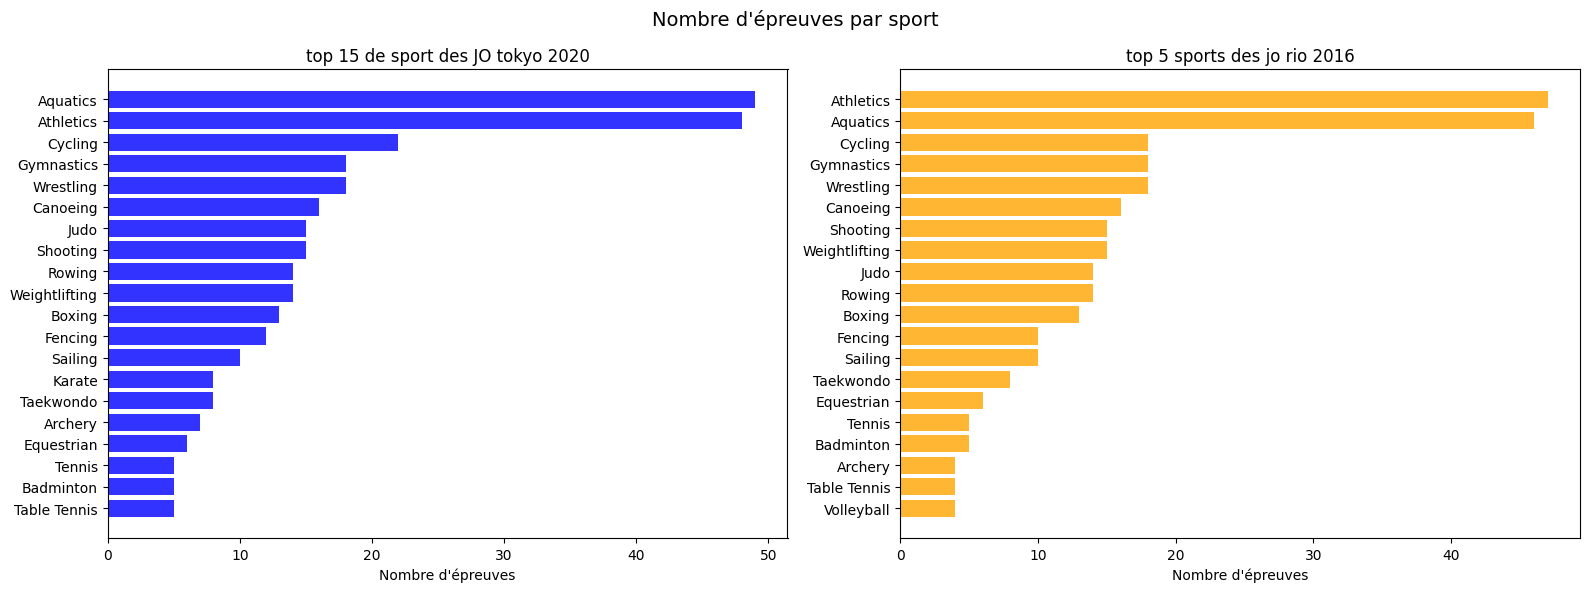

 l'athlétisme et la natation sont les sports les plus représentés. Les nouveaux sports de Tokyo (skateboard, surf, escalade sportive) témoignent de la volonté d'attirer un public et de diversifier le programme.



In [54]:
# Requête : nombre d'épreuves par sport pour une édition
def epreuves_par_sport(conn, id_hote):
    requete = f"""
        SELECT S.NomSport,
        COUNT(DISTINCT E.IdEvenement) AS NBEPREUVES
        FROM {SCHEMA}.EVENEMENT E
        INNER JOIN {SCHEMA}.DISCIPLINE D ON E.CodeDiscipline=D.CodeDiscipline
        INNER JOIN {SCHEMA}.SPORT S ON D.CodeSport=S.CodeSport
        WHERE E.IdHote=:id_hote
        GROUP BY S.NomSport
        ORDER BY NBEPREUVES DESC
    """
    return requete_vers_dataframe(conn, requete, {"id_hote": id_hote})

ep_tok=epreuves_par_sport(conn, id_hote_tokyo).head(20)
ep_rio=epreuves_par_sport(conn, id_hote_rio).head(20)

fig,axes=plt.subplots(1,2, figsize=(16,6))
for ax,df,titre,color in zip(
        axes,
        [ep_tok, ep_rio],
        ["top 15 de sport des JO tokyo 2020", "top 5 sports des jo rio 2016"],
        ["blue", "orange"]):
    df_s = df.sort_values("NBEPREUVES")
    ax.barh(df_s["NOMSPORT"], df_s["NBEPREUVES"], color=color, alpha=0.8)
    ax.set_title(titre, fontsize=12)
    ax.set_xlabel("Nombre d'épreuves")

plt.suptitle("Nombre d'épreuves par sport", fontsize=14)
plt.tight_layout()
plt.show()

print(""" l'athlétisme et la natation sont les sports les plus représentés. Les nouveaux sports de Tokyo (skateboard, surf, escalade sportive) témoignent de la volonté d'attirer un public et de diversifier le programme.
""")

In [55]:
synthese=pd.DataFrame({
"Indicateur": [
"Type de JO",
"Pays hôte",
"Nombre de nations",
"Nombre d'athlètes",
"Nombre d'épreuves",
"Nombre de disciplines",
"1ère nation (or)",
"Nations médaillées",],
"Pyeongchang 2018 ": ["Hiver", "Corée du Sud", "93","2793","102", "15", "Norvège (14)", "31"],
"Rio 2016": ["Été", "Brésil","207", "11182", "306", "41", "USA (46)","87"],
"Tokyo 2020":["Été","Japon", "206", "11319", "339","49", "USA (39)","93"],
})
print(synthese.to_string(index=False))

           Indicateur Pyeongchang 2018  Rio 2016 Tokyo 2020
           Type de JO             Hiver      Été        Été
            Pays hôte      Corée du Sud   Brésil      Japon
    Nombre de nations                93      207        206
    Nombre d'athlètes              2793    11182      11319
    Nombre d'épreuves               102      306        339
Nombre de disciplines                15       41         49
     1ère nation (or)      Norvège (14) USA (46)   USA (39)
   Nations médaillées                31       87         93


### Bilan et interprétation

Dans cette comparaison entre Tokyo 2020, Rio 2016 et PyeongChang 2018, on observe plusieurs tendances.


**Féminisation en progression.** Le pourcentage des femme parmi les athlètes a progressé d'édition en édition pour approcher la parité quasi parfaite lors des JO de l'édition Tokyo 2020. 

**Enrichissement du programme.**  On assisite à une apparition des sports urbains traduisent la stratégie du CIO de rajeunir l'audience olympique. Les discipilines traditionnelles sont toujours bien présentes.

**Effet hôte bien visible** On observe que le Japon réalise son meilleur résultat historique en or à Tokyo 2020

**Contexte exceptionnel de Tokyo.** Malgré la pandémie mondiale du COVID-19, les Jeux de Tokyo restent une édition très suivie et démontrent la résilience du mouvement olympique face à cette situation.

# 3.1 - Recuperation des editions d'ete passees

On récupere d'abord la liste des edition d'éte qui ont eu lieu avant. Cela va nous servir de base pour toutes les analyses qui suivent.

In [8]:
editions = requete_vers_dataframe(conn, f"""
    SELECT idhote AS "IdHote", anneehote AS "Annee", villehote AS "Ville"
    FROM {SCHEMA}.HOTE
    WHERE UPPER(saison) = 'SUMMER'
    AND anneehote <= 2020
    ORDER BY anneehote
""")
editions

,IdHote,Annee,Ville
0,1,1896,Athina
1,2,1900,Paris
2,3,1904,St. Louis
3,5,1908,London
4,6,1912,Stockholm
5,50,1916,Berlin
6,7,1920,Antwerpen
7,8,1924,Paris
8,9,1928,Amsterdam
9,10,1932,Los Angeles


# 3.2 - Evolution du nombre d'athletes espagnols

On commence par regarder combien d'athletes espagnols ont participe a chaque edition des JO d'ete. On compte un athlete une seule fois par edition, meme s'il participe a plusieurs epreuves (d'ou le DISTINCT).

In [9]:
athletes_esp = requete_vers_dataframe(conn, f"""
    SELECT h.anneehote AS "Annee",
           COUNT(DISTINCT pi.idathlete) AS "NbAthletes"
    FROM {SCHEMA}.PARTICIPATION_INDIVIDUELLE pi
    JOIN {SCHEMA}.EVENEMENT e ON pi.idevent = e.idevenement
    JOIN {SCHEMA}.HOTE h ON e.idhote = h.idhote
    WHERE UPPER(h.saison) = 'SUMMER'
    AND h.anneehote <= 2020
    AND pi.noc = 'ESP'
    GROUP BY h.anneehote
    ORDER BY h.anneehote
""")
athletes_esp

,Annee,NbAthletes
0,1900,5
1,1920,27
2,1924,70
3,1928,34
4,1932,7
5,1948,54
6,1952,24
7,1960,86
8,1964,34
9,1968,50


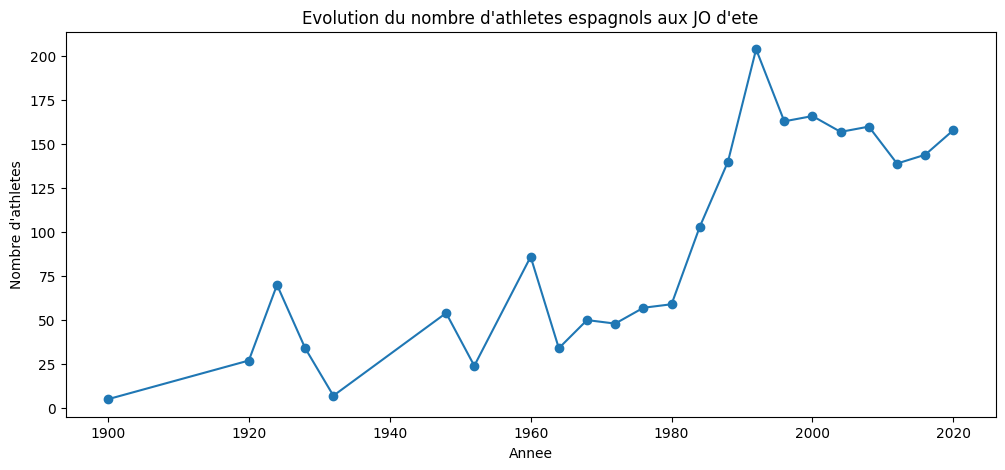

In [10]:
# graphique : evolution du nombre d'athletes espagnols
plt.figure(figsize=(12, 5))
plt.plot(athletes_esp["Annee"], athletes_esp["NbAthletes"], marker='o')
plt.title("Evolution du nombre d'athletes espagnols aux JO d'ete")
plt.xlabel("Annee")
plt.ylabel("Nombre d'athletes")
plt.show()

 On voit que la delegation espagnole a fortement grandi au fil du temps. Le pic historique a ete atteint lors des JO de Barcelone 1992 (organises en Espagne), avec un nombre record d'athletes. Depuis, la delegation s'est stabilisee autour de 250-350 athletes selon les editions.

# 3.3  Evolution du nombre de medailles espagnoles

Maintenant on regarde le nombre total de medailles remportees par l'Espagne a chaque edition. Pour compter correctement, on fait deux requetes puis on les additionne :
- Les medailles individuelles (PARTICIPATION_INDIVIDUELLE)
- Les medailles d'equipe (PARTICIPATION_EQUIPE, via EQUIPE filtree sur NOC=ESP)

In [11]:
# medailles individuelles de l'espagne par edition
med_indiv = requete_vers_dataframe(conn, f"""
    SELECT h.anneehote AS "Annee",
           SUM(CASE WHEN pi.medaille = 'Gold'   THEN 1 ELSE 0 END) AS "Or",
           SUM(CASE WHEN pi.medaille = 'Silver' THEN 1 ELSE 0 END) AS "Argent",
           SUM(CASE WHEN pi.medaille = 'Bronze' THEN 1 ELSE 0 END) AS "Bronze"
    FROM {SCHEMA}.PARTICIPATION_INDIVIDUELLE pi
    JOIN {SCHEMA}.EVENEMENT e ON pi.idevent = e.idevenement
    JOIN {SCHEMA}.HOTE h ON e.idhote = h.idhote
    WHERE UPPER(h.saison) = 'SUMMER'
    AND h.anneehote <= 2020
    AND pi.noc = 'ESP'
    AND pi.medaille IN ('Gold', 'Silver', 'Bronze')
    GROUP BY h.anneehote
    ORDER BY h.anneehote
""")
med_indiv

,Annee,Or,Argent,Bronze
0,1932,0,0,1
1,1952,0,1,0
2,1972,0,0,1
3,1980,0,1,1
4,1984,0,0,1
5,1988,1,0,2
6,1992,7,5,2
7,1996,1,5,4
8,2000,3,2,3
9,2004,2,7,5


In [12]:
# medailles d'equipe de l'espagne par edition
# on utilise DISTINCT sur idequipe car une medaille d'equipe = 1 medaille (pas une par athlete)
med_equipe = requete_vers_dataframe(conn, f"""
    SELECT h.anneehote AS "Annee",
           SUM(CASE WHEN pe.medaille = 'Gold'   THEN 1 ELSE 0 END) AS "Or",
           SUM(CASE WHEN pe.medaille = 'Silver' THEN 1 ELSE 0 END) AS "Argent",
           SUM(CASE WHEN pe.medaille = 'Bronze' THEN 1 ELSE 0 END) AS "Bronze"
    FROM {SCHEMA}.PARTICIPATION_EQUIPE pe
    JOIN {SCHEMA}.EQUIPE eq ON pe.idequipe = eq.idequipe
    JOIN {SCHEMA}.EVENEMENT e ON pe.idevenement = e.idevenement
    JOIN {SCHEMA}.HOTE h ON e.idhote = h.idhote
    WHERE UPPER(h.saison) = 'SUMMER'
    AND h.anneehote <= 2020
    AND eq.noc = 'ESP'
    AND pe.medaille IN ('Gold', 'Silver', 'Bronze')
    GROUP BY h.anneehote
    ORDER BY h.anneehote
""")
med_equipe

,Annee,Or,Argent,Bronze
0,1900,1,0,0
1,1920,0,2,0
2,1928,1,0,0
3,1948,0,1,0
4,1960,0,0,1
5,1976,0,2,0
6,1980,1,2,1
7,1984,1,2,1
8,1988,0,1,0
9,1992,6,2,0


In [13]:
# on additionne les deux tableaux pour avoir le total par edition
#jointure sur l'annéee
med_total = pd.merge(med_indiv, med_equipe, on="Annee", how="outer", suffixes=("_ind", "_eq")).fillna(0)
med_total["Or"] = med_total["Or_ind"] + med_total["Or_eq"]
med_total["Argent"] = med_total["Argent_ind"] + med_total["Argent_eq"]
med_total["Bronze"] = med_total["Bronze_ind"] + med_total["Bronze_eq"]
med_total["Total"] = med_total["Or"] + med_total["Argent"] + med_total["Bronze"]
med_total = med_total[["Annee", "Or", "Argent", "Bronze", "Total"]].sort_values("Annee")
med_total

,Annee,Or,Argent,Bronze,Total
0,1900,1.0,0.0,0.0,1.0
1,1920,0.0,2.0,0.0,2.0
2,1928,1.0,0.0,0.0,1.0
3,1932,0.0,0.0,1.0,1.0
4,1948,0.0,1.0,0.0,1.0
5,1952,0.0,1.0,0.0,1.0
6,1960,0.0,0.0,1.0,1.0
7,1972,0.0,0.0,1.0,1.0
8,1976,0.0,2.0,0.0,2.0
9,1980,1.0,3.0,2.0,6.0


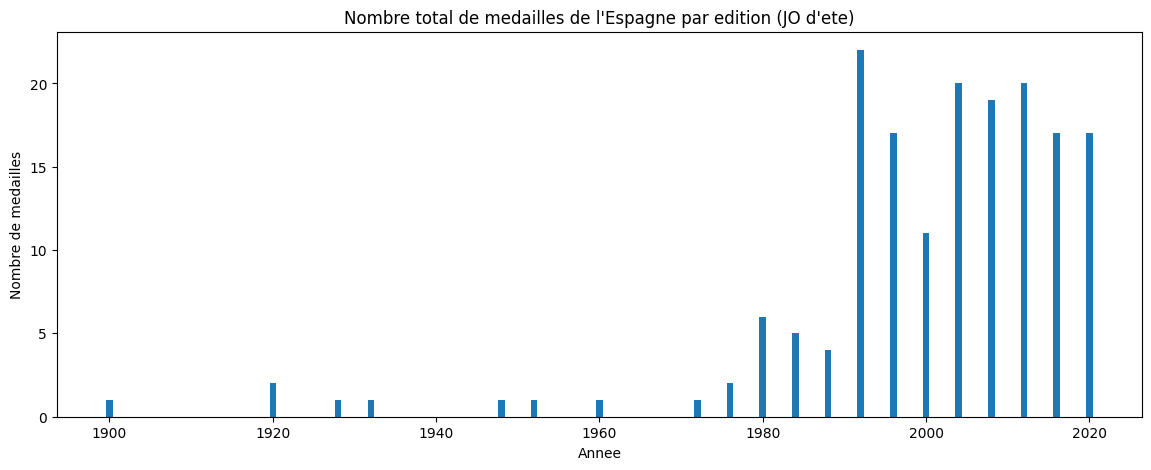

In [14]:
# graphique en barres : médailles par edition
plt.figure(figsize=(14, 5))
plt.bar(med_total["Annee"], med_total["Total"])
plt.title("Nombre total de medailles de l'Espagne par edition (JO d'ete)")
plt.xlabel("Annee")
plt.ylabel("Nombre de medailles")
plt.show()

L'Espagne n'a pratiquement pas gagne de medailles avant les annees 1980. Les JO de Barcelone 1992 ont ete un vrai tournant : avec 22 medailles remportees a domicile, c'est le record absolu de l'histoire olympique espagnole. Depuis, le pays se maintient entre 15 et 20 medailles par edition, avec une legere baisse a Tokyo 2020.

# 3.4 - Repartition des medailles par type (or/argent/bronze)

On regarde maintenant la repartition par type de medaille pour voir si l'Espagne brille plus en or ou en bronze.

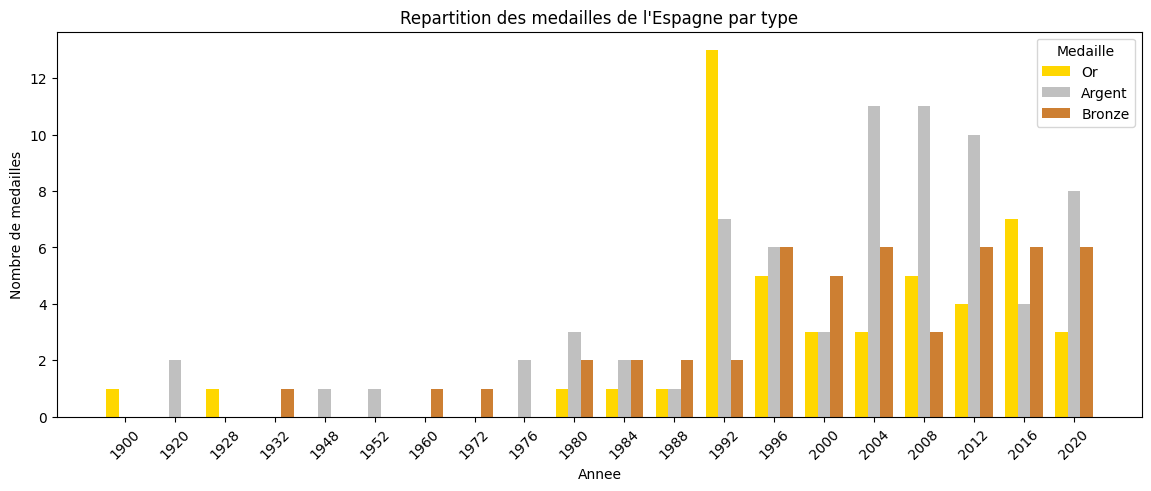

In [15]:
# graphique en barres avec 3 couleurs pour or / argent / bronze
x = range(len(med_total["Annee"]))

plt.figure(figsize=(14, 5))
plt.bar([i - 0.25 for i in x], med_total["Or"],     width=0.25, label="Or",     color="gold")
plt.bar([i        for i in x], med_total["Argent"], width=0.25, label="Argent", color="silver")
plt.bar([i + 0.25 for i in x], med_total["Bronze"], width=0.25, label="Bronze", color="#cd7f32")
plt.xticks(x, med_total["Annee"], rotation=45)
plt.title("Repartition des medailles de l'Espagne par type")
plt.xlabel("Annee")
plt.ylabel("Nombre de medailles")
plt.legend(title="Medaille")
plt.show()

 L'Espagne gagne globalement plus de medailles d'argent et de bronze que d'or, ce qui est typique des pays qui ne sont pas dans le top 5 mondial. Le plus gros pic d'or reste Barcelone 1992.

## 3.5 - Calculs statistiques (ecart-type et moyenne)

Pour resumer ces chiffres, on calcule la moyenne et l'ecart-type du nombre total de medailles par edition.

In [18]:
# on recupere la liste des totaux de medailles
medailles = list(med_total["Total"])
print("Medailles par edition :", medailles)

# moyenne 
somme = 0
for m in medailles:
    somme = somme + m
moyenne = somme / len(medailles)
print(f"Moyenne : {moyenne:.2f} medailles par edition")

# ecart-type 
somme_carres = 0
for m in medailles:
    somme_carres = somme_carres + (m - moyenne) ** 2
variance = somme_carres / len(medailles)
ecart_type = math.sqrt(variance)
print(f"Ecart-type : {ecart_type:.2f}")

Medailles par edition : [1.0, 2.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0, 6.0, 5.0, 4.0, 22.0, 17.0, 11.0, 20.0, 19.0, 20.0, 17.0, 17.0]
Moyenne : 8.45 medailles par edition
Ecart-type : 8.05


In [19]:
# on calcule aussi min / max / mediane pour avoir une vue plus complete
print(f"Minimum : {min(medailles)} medailles")
print(f"Maximum : {max(medailles)} medailles")

# mediane a la main : on trie et on prend la valeur du milieu
medailles_triees = sorted(medailles)
n = len(medailles_triees)
if n % 2 == 1:
    mediane = medailles_triees[n // 2]
else:
    mediane = (medailles_triees[n // 2 - 1] + medailles_triees[n // 2]) / 2
print(f"Mediane : {mediane}")

Minimum : 1.0 medailles
Maximum : 22.0 medailles
Mediane : 4.5


**Interpretation :** La moyenne inclut toutes les editions, y compris les tres anciennes ou l'Espagne ne gagnait presque rien. L'ecart-type est assez eleve, ce qui confirme que les performances ont fortement varie au cours du temps. Pour faire une projection realiste, il vaut mieux se baser uniquement sur les editions recentes.

## 3.6 - Projection pour les JO de Paris 2024

Pour estimer les performances de l'Espagne a la prochaine edition (Paris 2024), on se base sur la moyenne des **4 dernieres editions** (2008, 2012, 2016, 2020). On ecarte les editions anciennes qui ne sont pas representatives du niveau actuel du pays.

In [20]:
# on ne garde que les 4 dernieres editions
recentes = med_total[med_total["Annee"] >= 2008]
print("Dernieres editions prises en compte :")
print(recentes[["Annee", "Or", "Argent", "Bronze", "Total"]])

# moyenne des medailles recentes (on peut utiliser pandas maintenant car on a deja fait le calcul a la main plus haut)
moy_or     = recentes["Or"].mean()
moy_argent = recentes["Argent"].mean()
moy_bronze = recentes["Bronze"].mean()
moy_total  = recentes["Total"].mean()

print("\n  Projection pour Paris 2024 ")
print(f"Or     (projection) : {moy_or:.1f}")
print(f"Argent (projection) : {moy_argent:.1f}")
print(f"Bronze (projection) : {moy_bronze:.1f}")
print(f"Total  (projection) : {moy_total:.1f} medailles")

Dernieres editions prises en compte :
    Annee   Or  Argent  Bronze  Total
16   2008  5.0    11.0     3.0   19.0
17   2012  4.0    10.0     6.0   20.0
18   2016  7.0     4.0     6.0   17.0
19   2020  3.0     8.0     6.0   17.0

  Projection pour Paris 2024 
Or     (projection) : 4.8
Argent (projection) : 8.2
Bronze (projection) : 5.2
Total  (projection) : 18.2 medailles


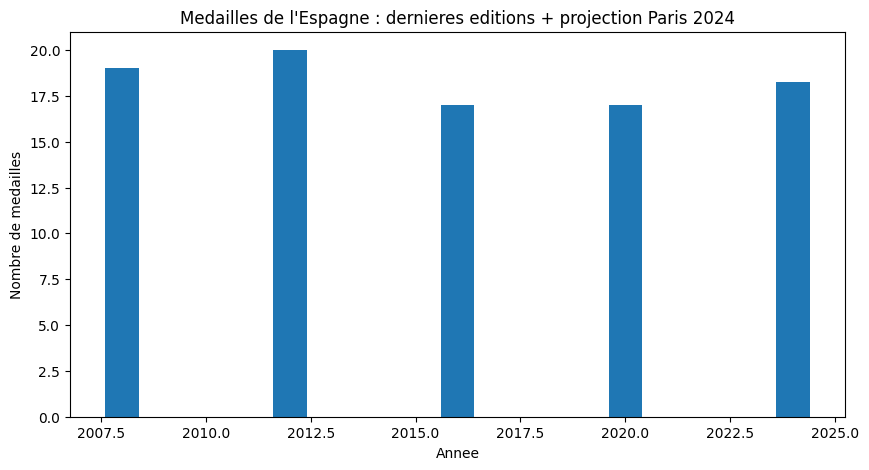

In [21]:
# graphique de comparaison : dernieres editions + projection 2024
annees = list(recentes["Annee"]) + [2024]
totaux = list(recentes["Total"]) + [moy_total]

plt.figure(figsize=(10, 5))
plt.bar(annees, totaux)
plt.title("Medailles de l'Espagne : dernieres editions + projection Paris 2024")
plt.xlabel("Annee")
plt.ylabel("Nombre de medailles")
plt.show()

 D'apres notre analyse basee sur la moyenne des 4 dernieres editions, on peut estimer que l'Espagne devrait remporter environ 15 a 18 medailles aux JO de Paris 2024. Plusieurs facteurs peuvent cependant faire varier ce chiffre :

- La proximite geographique avec la France pourrait jouer en faveur de l'Espagne (deplacement plus facile des athletes et du public, moins de fatigue).
- Le niveau de preparation et l'investissement du pays dans le sport de haut niveau.
- Les disciplines historiquement fortes pour l'Espagne (football, basket, tennis, voile, cyclisme, natation synchronisee) resteront les principaux pourvoyeurs de medailles.

# Conclusion

L'Espagne est une nation dont les performances olympiques ont fortement evolue depuis les annees 1980. Apres un tournant historique a Barcelone 1992, le pays s'est installe comme une nation intermediaire, avec une regularite autour de 15-20 medailles par edition. Notre projection pour Paris 2024 confirme cette tendance, en attendant de voir si la proximite du pays hote pourra booster les performances.